In [28]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [30]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "TotalCharges"]]

11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


In [31]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())
df["TotalCharges"].dtype

0


dtype('float64')

In [32]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [33]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())
df["TotalCharges"].dtype

0


dtype('float64')

In [34]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [35]:
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
for c in service_cols:
    df[c] = df[c].replace("No internet service", "No")

df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

df["OnlineSecurity"].value_counts()

OnlineSecurity
No     5024
Yes    2019
Name: count, dtype: int64

In [36]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["SeniorCitizen"].value_counts()

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64

In [37]:
df.to_csv("../data/telco_clean.csv", index=False)
print("saved")

saved


In [38]:
import sqlite3

conn = sqlite3.connect("../data/churn.db")
df.to_sql("customers", conn, if_exists="replace", index=False)
print("done")

done


In [39]:
query = """
SELECT Churn, COUNT(*) as total
FROM customers
GROUP BY Churn
"""
pd.read_sql(query, conn)

,Churn,total
0,0,5174
1,1,1869


In [40]:
query = """
SELECT Churn, COUNT(*) as total
FROM customers
GROUP BY Churn
"""
pd.read_sql(query, conn)

,Churn,total
0,0,5174
1,1,1869


In [41]:
query = """
SELECT Contract,
       COUNT(*) as total_customers,
       SUM(Churn) as churned,
       ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY Contract
"""
pd.read_sql(query, conn)

,Contract,total_customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.7
1,One year,1473,166,11.3
2,Two year,1695,48,2.8


In [42]:
query = """
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 months'
        WHEN tenure <= 24 THEN '12-24 months'
        WHEN tenure <= 48 THEN '24-48 months'
        ELSE '48+ months'
    END as tenure_group,
    COUNT(*) as total_customers,
    SUM(Churn) as churned,
    ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY tenure_group
ORDER BY churn_rate_pct DESC
"""
pd.read_sql(query, conn)

,tenure_group,total_customers,churned,churn_rate_pct
0,0-12 months,2186,1037,47.4
1,12-24 months,1024,294,28.7
2,24-48 months,1594,325,20.4
3,48+ months,2239,213,9.5


In [43]:
query = """
SELECT
    CASE
        WHEN MonthlyCharges < 35 THEN 'Low (<$35)'
        WHEN MonthlyCharges < 70 THEN 'Medium ($35-70)'
        ELSE 'High ($70+)'
    END as charge_group,
    COUNT(*) as total_customers,
    SUM(Churn) as churned,
    ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY charge_group
ORDER BY churn_rate_pct DESC
"""
pd.read_sql(query, conn)

,charge_group,total_customers,churned,churn_rate_pct
0,High ($70+),3591,1274,35.5
1,Medium ($35-70),1721,407,23.6
2,Low (<$35),1731,188,10.9


In [44]:
query = """
SELECT
    InternetService,
    TechSupport,
    COUNT(*) as total_customers,
    SUM(Churn) as churned,
    ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY InternetService, TechSupport
ORDER BY churn_rate_pct DESC
"""
pd.read_sql(query, conn)

,InternetService,TechSupport,total_customers,churned,churn_rate_pct
0,Fiber optic,No,2230,1101,49.4
1,DSL,No,1243,345,27.8
2,Fiber optic,Yes,866,196,22.6
3,DSL,Yes,1178,114,9.7
4,No,No,1526,113,7.4


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

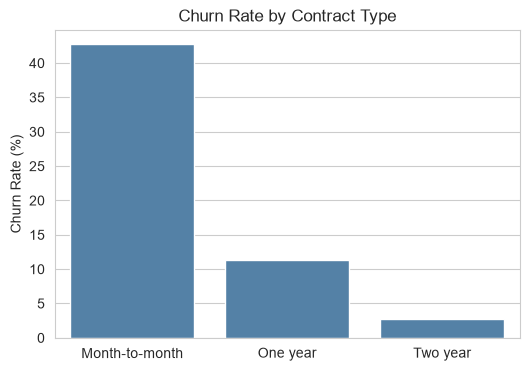

In [46]:
query = """
SELECT Contract,
       ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY Contract
"""
contract_data = pd.read_sql(query, conn)

plt.figure(figsize=(6,4))
sns.barplot(data=contract_data, x="Contract", y="churn_rate_pct", color="steelblue")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xlabel("")
plt.show()

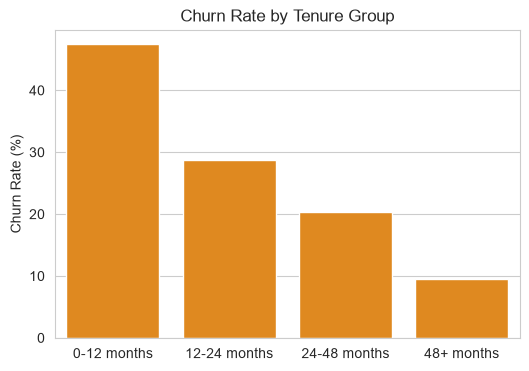

In [47]:
query = """
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 months'
        WHEN tenure <= 24 THEN '12-24 months'
        WHEN tenure <= 48 THEN '24-48 months'
        ELSE '48+ months'
    END as tenure_group,
    ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY tenure_group
"""
tenure_data = pd.read_sql(query, conn)

order = ['0-12 months', '12-24 months', '24-48 months', '48+ months']
plt.figure(figsize=(6,4))
sns.barplot(data=tenure_data, x="tenure_group", y="churn_rate_pct", order=order, color="darkorange")
plt.title("Churn Rate by Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xlabel("")
plt.show()

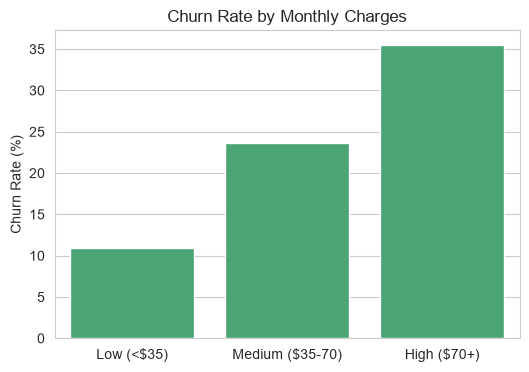

In [48]:
query = """
SELECT
    CASE
        WHEN MonthlyCharges < 35 THEN 'Low (<$35)'
        WHEN MonthlyCharges < 70 THEN 'Medium ($35-70)'
        ELSE 'High ($70+)'
    END as charge_group,
    ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY charge_group
"""
charge_data = pd.read_sql(query, conn)

order = ['Low (<$35)', 'Medium ($35-70)', 'High ($70+)']
plt.figure(figsize=(6,4))
sns.barplot(data=charge_data, x="charge_group", y="churn_rate_pct", order=order, color="mediumseagreen")
plt.title("Churn Rate by Monthly Charges")
plt.ylabel("Churn Rate (%)")
plt.xlabel("")
plt.show()

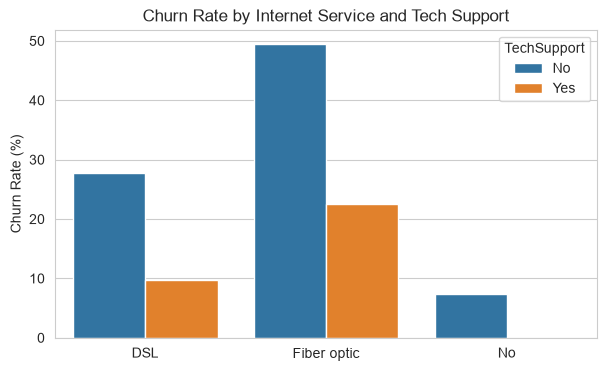

In [49]:
query = """
SELECT InternetService, TechSupport,
       ROUND(100.0 * SUM(Churn) / COUNT(*), 1) as churn_rate_pct
FROM customers
GROUP BY InternetService, TechSupport
"""
service_data = pd.read_sql(query, conn)

plt.figure(figsize=(7,4))
sns.barplot(data=service_data, x="InternetService", y="churn_rate_pct", hue="TechSupport")
plt.title("Churn Rate by Internet Service and Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xlabel("")
plt.show()

In [50]:
model_df = df.drop(columns=["customerID"])
model_df = pd.get_dummies(model_df, drop_first=True)
model_df.shape

(7043, 24)

In [51]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(5634, 23) (1409, 23)


In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)
y_proba = log_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8422692397116949


c:\Users\HP\OneDrive\Desktop\churn project\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [53]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.56      0.66      0.61       374

    accuracy                           0.77      1409
   macro avg       0.72      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409

ROC-AUC: 0.8261024567929938


In [54]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.56      0.66      0.61       374

    accuracy                           0.77      1409
   macro avg       0.72      0.74      0.72      1409
weighted avg       0.79      0.77      0.78      1409

ROC-AUC: 0.8261024567929938


In [55]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                          scale_pos_weight=ratio, random_state=42, eval_metric="logloss")
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_xgb))

              precision    recall  f1-score   support

           0       0.91      0.72      0.81      1035
           1       0.51      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

ROC-AUC: 0.8442183988219795


In [56]:
import joblib

joblib.dump(xgb_model, "../models/xgb_model.pkl")
joblib.dump(list(X_train.columns), "../models/feature_columns.pkl")
print("saved")

saved


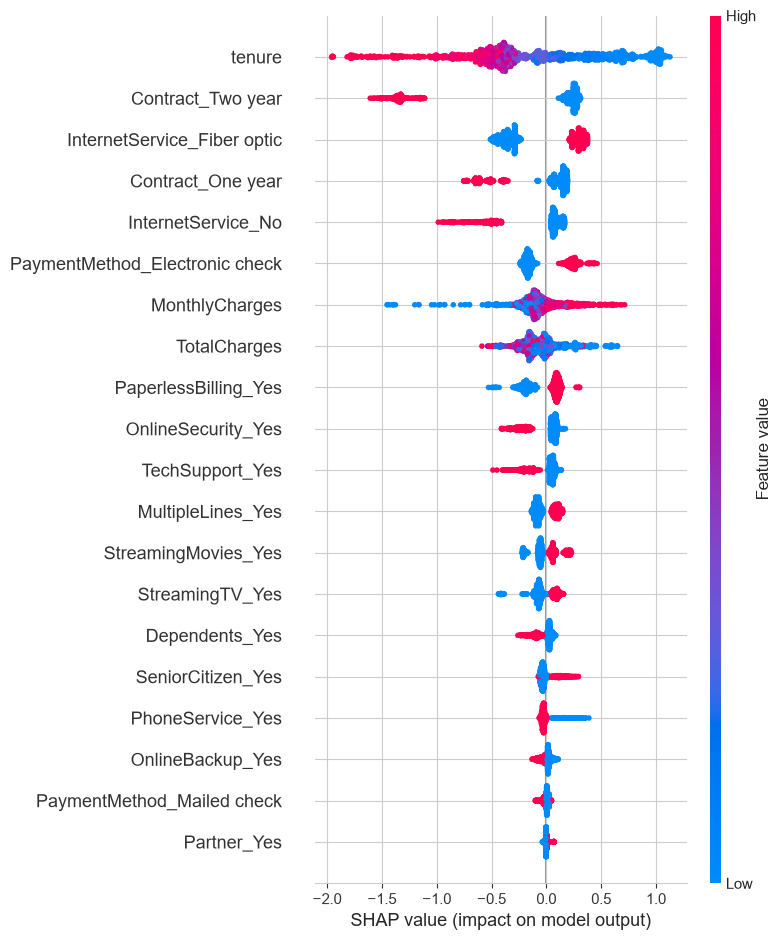

In [57]:
import shap

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

In [58]:
import streamlit as st
import pandas as pd
from pathlib import Path

BASE = Path(__file__).parent.parent
df = pd.read_csv(BASE / "data" / "telco_clean.csv")

st.set_page_config(page_title="Churn Dashboard", layout="wide")
st.title("Customer Churn Dashboard")

# Filters (left sidebar)
contracts = sorted(df["Contract"].unique())
internets = sorted(df["InternetService"].unique())
sel_contract = st.sidebar.multiselect("Contract", contracts, default=contracts)
sel_internet = st.sidebar.multiselect("Internet Service", internets, default=internets)

filtered = df[df["Contract"].isin(sel_contract) & df["InternetService"].isin(sel_internet)]

if filtered.empty:
    st.warning("Koi customer nahi mila, filters badlo.")
    st.stop()

# KPI cards
c1, c2, c3 = st.columns(3)
c1.metric("Customers", f"{len(filtered):,}")
c2.metric("Churn rate", f"{filtered['Churn'].mean() * 100:.1f}%")
lost = filtered.loc[filtered["Churn"] == 1, "MonthlyCharges"].sum()
c3.metric("Monthly revenue lost", f"${lost:,.0f}")

# Chart
st.subheader("Churn rate by contract type (%)")
st.bar_chart(filtered.groupby("Contract")["Churn"].mean() * 100)

NameError: name '__file__' is not defined